# Split train/test de sujetos — Sleep Cassette - (Microproyecto/Entrega 1)

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

***Objetivo:*** Análisis de `SC-subjects.xls` para detectar sesgos antes de definir el split, y generación de `SC-subjects-split.xls` con una columna `split` (`"train"`/`"test"`) asignada a nivel de **sujeto** (nunca a nivel de noche/grabación individual, para que las 2 noches de un mismo sujeto queden siempre del mismo lado).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from pathlib import Path
import sys
import os

In [3]:
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

ROOT_PATH = project_root / "data/sleep-edfx/"

In [15]:
from src.data.segmentation import (
    extract_epochs,
    concatenate_datasets,
    class_distribution,
    INT_TO_CLASS,
    concatenate_datasets_by_split
)

In [4]:
SRC_PATH = "SC-subjects.xls"
OUT_PATH = "SC-subjects-split.xlsx"
RANDOM_STATE = 42
TEST_SIZE = 0.2

## 1. Cargar y explorar

In [5]:
df = pd.read_excel(ROOT_PATH / SRC_PATH)
print(df.shape, "filas (sujeto x noche)")
df.head()

(153, 5) filas (sujeto x noche)


,subject,night,age,sex (F=1),LightsOff
0,0,1,33,1,00:38:00
1,0,2,33,1,21:57:00
2,1,1,33,1,22:44:00
3,1,2,33,1,22:15:00
4,2,1,26,1,22:50:00


In [6]:
per_subject = (
    df.groupby("subject")
    .agg(age=("age", "first"), sex=("sex (F=1)", "first"))
    .reset_index()
)
print(f"{per_subject.shape[0]} sujetos únicos (numeración 0-{per_subject['subject'].max()}, con huecos)")
print("Edad:", per_subject['age'].min(), "-", per_subject['age'].max(), "| media:", round(per_subject['age'].mean(),1))
print("\nSexo (1=F, 2=M):")
print(per_subject['sex'].value_counts())

78 sujetos únicos (numeración 0-82, con huecos)
Edad: 25 - 101 | media: 58.8

Sexo (1=F, 2=M):
sex
1    41
2    37
Name: count, dtype: int64


Detectar sesgo por orden de secuencia. El estudio recluta sujetos para comparar **efectos de la edad en el sueño** por lo que se que verifica si el número de sujeto está correlacionado con la edad (lo cual invalidaría un split por rango de número, como `00-69` train / `70-83` test).

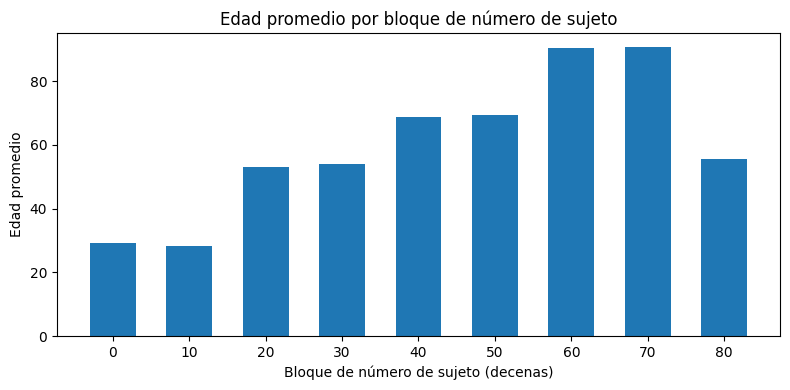

decade_block
0     29.1
10    28.2
20    53.0
30    54.0
40    68.8
50    69.3
60    90.5
70    90.6
80    55.7
Name: age, dtype: float64


In [7]:
per_subject["decade_block"] = (per_subject["subject"] // 10) * 10
age_by_block = per_subject.groupby("decade_block")["age"].mean()

plt.figure(figsize=(8, 4))
plt.bar(age_by_block.index.astype(str), age_by_block.values, width=0.6)
plt.xlabel("Bloque de número de sujeto (decenas)")
plt.ylabel("Edad promedio")
plt.title("Edad promedio por bloque de número de sujeto")
plt.tight_layout()
plt.show()

print(age_by_block.round(1))

**Conclusión**: la edad promedio sube claramente con el número de sujeto (de ~28 años en 00-19 a ~90 años en 60-79) — confirma que los sujetos fueron reclutados en orden de edad. Un split por rango de número (p. ej. 00-69 vs 70-83) dejaría casi todos los adultos mayores en un solo lado. Por eso el split se hace **estratificado por edad y sexo**, no por rango.

## Split estratificado por edad + sexo

In [8]:
# Bins de edad para estratificar (cuartiles, para no asumir cohortes fijas)
per_subject["age_bin"] = pd.qcut(per_subject["age"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])

# Combinar edad + sexo en una sola etiqueta de estratificación
per_subject["strata"] = per_subject["age_bin"].astype(str) + "_sex" + per_subject["sex"].astype(str)

print(per_subject["strata"].value_counts().sort_index())

strata
Q1_sex1    10
Q1_sex2    10
Q2_sex1    13
Q2_sex2     8
Q3_sex1     7
Q3_sex2    10
Q4_sex1    11
Q4_sex2     9
Name: count, dtype: int64


In [9]:
train_subjects, test_subjects = train_test_split(
    per_subject["subject"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=per_subject["strata"],
)

per_subject["split"] = np.where(per_subject["subject"].isin(train_subjects), "train", "test")

print(f"Train: {len(train_subjects)} sujetos | Test: {len(test_subjects)} sujetos")
per_subject["split"].value_counts()

Train: 62 sujetos | Test: 16 sujetos


split
train    62
test     16
Name: count, dtype: int64

## Verificar que el split quedó balanceado

In [10]:
print("Edad promedio por split:")
print(per_subject.groupby("split")["age"].mean().round(1))

print("\nEdad — resumen completo por split:")
print(per_subject.groupby("split")["age"].describe()[["min", "25%", "50%", "75%", "max"]].round(1))

print("\nSexo por split:")
print(pd.crosstab(per_subject["split"], per_subject["sex"]))

Edad promedio por split:
split
test     59.7
train    58.6
Name: age, dtype: float64

Edad — resumen completo por split:
        min   25%   50%   75%    max
split                               
test   28.0  46.8  55.5  76.0   92.0
train  25.0  37.2  57.0  72.5  101.0

Sexo por split:
sex     1   2
split        
test    8   8
train  33  29


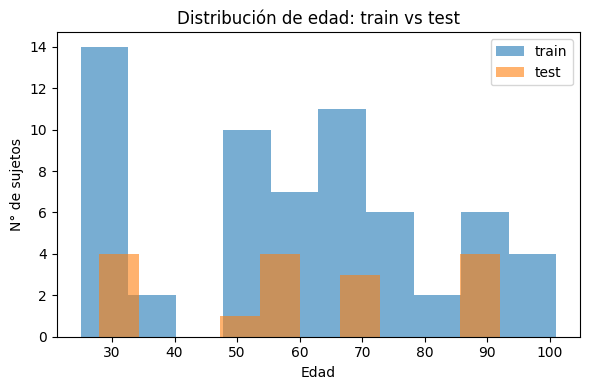

In [11]:
plt.figure(figsize=(6, 4))
for split_name, color in [("train", "tab:blue"), ("test", "tab:orange")]:
    subset = per_subject[per_subject["split"] == split_name]["age"]
    plt.hist(subset, bins=10, alpha=0.6, label=split_name, color=color)
plt.xlabel("Edad")
plt.ylabel("N° de sujetos")
plt.title("Distribución de edad: train vs test")
plt.legend()
plt.tight_layout()
plt.show()

## Guardar `SC-subjects-split.xls`
Se propaga el `split` a las **153 filas originales** (ambas noches por sujeto), manteniendo todas las columnas originales + la nueva columna `split`.

In [12]:
df_final = df.merge(per_subject[["subject", "split"]], on="subject", how="left")

assert df_final["split"].isna().sum() == 0, "Hay filas sin split asignado"
assert df_final.groupby("subject")["split"].nunique().max() == 1, \
    "Un mismo sujeto quedó con las dos noches en splits distintos"

print(df_final.shape)
df_final.head(10)

(153, 6)


,subject,night,age,sex (F=1),LightsOff,split
0,0,1,33,1,00:38:00,train
1,0,2,33,1,21:57:00,train
2,1,1,33,1,22:44:00,train
3,1,2,33,1,22:15:00,train
4,2,1,26,1,22:50:00,train
5,2,2,26,1,22:57:00,train
6,3,1,26,1,00:02:00,train
7,3,2,26,1,00:24:00,train
8,4,1,34,1,23:12:00,test
9,4,2,34,1,23:35:00,test


In [13]:
df_final.to_excel(ROOT_PATH / OUT_PATH, index=False)
print(f"Guardado: {OUT_PATH}")

# Verificación de lectura
check = pd.read_excel(ROOT_PATH / OUT_PATH)
print(check["split"].value_counts())
check.head()

Guardado: SC-subjects-split.xlsx
split
train    121
test      32
Name: count, dtype: int64


,subject,night,age,sex (F=1),LightsOff,split
0,0,1,33,1,00:38:00,train
1,0,2,33,1,21:57:00,train
2,1,1,33,1,22:44:00,train
3,1,2,33,1,22:15:00,train
4,2,1,26,1,22:50:00,train


Comprobar que ningun sujeto aparece en test y train

In [14]:
df = pd.read_excel(ROOT_PATH / OUT_PATH)

# Un sujeto puede aparecer hasta 2 veces (2 noches) -> debe tener SIEMPRE el mismo split
splits_por_sujeto = df.groupby("subject")["split"].nunique()
sujetos_mezclados = splits_por_sujeto[splits_por_sujeto > 1]

if len(sujetos_mezclados) == 0:
    print("OK: ningún sujeto está repartido entre train y test.")
else:
    print(f"PROBLEMA: {len(sujetos_mezclados)} sujeto(s) aparecen en ambos splits:")
    print(sujetos_mezclados)

# Chequeo adicional: intersección directa de los sets de sujetos
train_subjects = set(df[df["split"] == "train"]["subject"])
test_subjects = set(df[df["split"] == "test"]["subject"])
interseccion = train_subjects & test_subjects
print(f"\nIntersección train/test: {interseccion if interseccion else 'vacía (correcto)'}")

OK: ningún sujeto está repartido entre train y test.

Intersección train/test: vacía (correcto)


In [16]:
# En un caso real, esto vendría de leer SC-subjects-split.xlsx:
#   import pandas as pd
#   split_df = pd.read_excel("SC-subjects-split.xlsx")
#   split_df["subject_code"] = split_df["subject"].astype(str).str.zfill(2)
#   subject_to_split = dict(zip(split_df["subject_code"], split_df["split"]))
#
# Para esta prueba rápida (con un solo sujeto real disponible), simulamos
# el mapeo a mano:
subject_to_split = {"00": "train", "01": "train", "02": "test"}

In [ ]:
## Simular varias grabaciones (en tu caso real, cada una vendría de un load_subject + extract_epochs distinto)

ds_a = extract_epochs(subject.raw, subject.annotations, recording_id="SC4001E0", channel_picks=["EEG Fpz-Cz"])
ds_b = extract_epochs(subject.raw, subject.annotations, recording_id="SC4011E0", channel_picks=["EEG Fpz-Cz"])
ds_c = extract_epochs(subject.raw, subject.annotations, recording_id="SC4022E0", channel_picks=["EEG Fpz-Cz"])

todas_las_grabaciones = [ds_a, ds_b, ds_c]